In [1]:
%matplotlib widget
%load_ext autoreload
%autoreload 2

from _path import NB_DIR
import sys
import os
from datetime import datetime
import pickle
import dill

sys.path.append(str(NB_DIR))

import pandas as pd
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt

from matal.recipe import UniformCompositionGenerator
from matal.utils import auto_log, get_sid, obj_to_hash, merge_update, Bunch, cache_return, load_cache
from matal.configs import BATCH_DIR, PROJ_CODE, MODEL_DIR, DATA_DIR
from matal.robot.ot2 import OT2ProcGeneratorV7


## 1. Load SVM model for sample composition filtering
1. The composition must passes all 3 screening models: solubility, HER and OER
2. The composition should not be too close to the design boundary (repersented by ```smooth_verts```)

In [2]:
svm_models = load_cache('svm_models_v6_patched')
display(svm_models)

X_COLS = ['cons_ZnCl2', 'cons_ZnOTF2', 'ratio_MeOH']
X_LIMS = np.array([35.0, 6.0, 1.0])

from matal.vis import marching_cubes, skimg_tri_to_poly, poly_to_skimg_tri, smooth_pvs_poly, get_mesh_pred

margin = 0.05
n_points = 331
pred_sol, grid_space, flattened = get_mesh_pred(svm_models['solubility'], margin=margin, n_points=n_points, target='pred')
pred_her, _, _ = get_mesh_pred(svm_models['HER'], margin=margin, n_points=n_points, target='pred', margin_value=-5.0)
pred_oer, _, _ = get_mesh_pred(svm_models['OER'], margin=margin, n_points=n_points, target='pred', margin_value= 5.0)

# Value cutoff 
oer_cutoff = 1.8
her_cutoff = -0.88

merge_pred = ((pred_sol >= 0.5) & (pred_oer >= oer_cutoff) & (pred_her >= her_cutoff)).astype(np.float16)
verts, faces, *_ = marching_cubes(merge_pred, 0.5, spacing=(grid_space, ) * 3, gradient_direction='ascent', allow_degenerate=False)
verts -= margin

# Smooth iso-plane
poly = skimg_tri_to_poly(verts, faces)
smooth_poly = smooth_pvs_poly(poly, sm_iters=500, sm_rlx=0.2, sm2_iters=50, sm2_rlx=0.05, dp_factor=0.95, dp_angle=120, dp_iters=100)
smooth_verts, smooth_faces = poly_to_skimg_tri(smooth_poly)
print(f'Num of edge points:', len(smooth_verts))

# Precalculated kDTree for fast distance computation
import scipy
kdtree = scipy.spatial.KDTree(smooth_verts)
kdtree

{'solubility': SVC(C=859.5792940061186, gamma=3.4589836312369657, probability=True,
     random_state=0),
 'HER': SVR(C=6.242440709438059, epsilon=0.004211530744928162, gamma=0.6547642454463255),
 'OER': SVR(C=3428.7083529537863, epsilon=0.009476443908631768,
     gamma=0.3892162087109403)}

Num of edge points: 18957


## 2. Generate new compositions using distance-based sampling

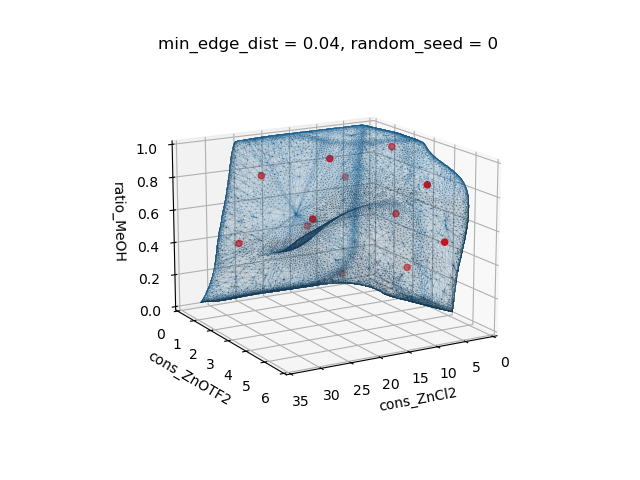

In [3]:
from tqdm.auto import tqdm
from scipy.spatial.distance import pdist, cdist, squareform
import copy
import warnings

# To ignore all UserWarnings
warnings.filterwarnings("ignore", category=UserWarning)

def filter_comp(comp, svm_models=svm_models, scale=X_LIMS, kdtree=None, min_dist=0, min_comp=0):
    comp = comp / scale
    sol = svm_models['solubility'].predict(comp)
    her = svm_models['HER'].predict(comp)
    oer = svm_models['OER'].predict(comp)
    mask = (sol & (her >= her_cutoff) & (oer >= oer_cutoff)).astype(bool)

    if (kdtree is not None) and (min_dist > 0.0):
        dist, min_idx = kdtree.query(comp)
        mask = mask & (dist > min_dist)

    if min_comp > 0.0:
        mask = mask & (comp.min(axis=1) > min_comp)

    return mask

def get_rand_comp(n=100, func=filter_comp, func_kw=dict(), batch_factor=8.0, max_iter=10, scale=X_LIMS, random_state=None, rng=None):
    if rng is None:
        rng = np.random.default_rng(random_state)
    comp = []
    for _ in range(max_iter):
        comp_i = (rng.random((round(n * batch_factor), len(scale))) * scale).round(2)
        if func is not None:
            mask = func(comp_i, **func_kw)
            comp_i = comp_i[mask]
        if len(comp_i) > 0:
            comp = np.vstack((comp, comp_i)) if len(comp) > 0 else comp_i
        if len(comp) >= n:
            break
    return comp[:n]

@cache_return
def opt_comps(*args, min_edge_dist=0.05, min_comp=0.02, **kwargs):
    warnings.filterwarnings("ignore", category=UserWarning)
    g = UniformCompositionGenerator(
        *args, 
        comp_gen_func=get_rand_comp,
        func_kw=dict(kdtree=kdtree, min_dist=min_edge_dist, min_comp=min_comp), 
        **kwargs)
    return g.optimize()


min_edge_dist = 0.04
random_seed = 0

batch_df = opt_comps(
    cols=X_COLS,
    n_comps=12,
    n_iters=200000,
    random_state=random_seed,
    dist_col_scales=1 / X_LIMS,
    min_edge_dist=min_edge_dist,
    min_comp=0.02
)

plt.close('all')
fig, ax = plt.subplots(1, 1, subplot_kw=dict(projection='3d'))

ax.plot_trisurf(*(smooth_verts * X_LIMS).T, triangles=smooth_faces, linewidth=0, 
                antialiased=False, alpha=0.1, color='tab:blue', label='HER-OER Model')
ax.scatter(*batch_df[X_COLS].values.T, c='red')

[getattr(ax, f'set_{a}label')(c) for a, c in zip('xyz', X_COLS)]
[getattr(ax, f'set_{a}lim')(0, l) for a, l in zip('xyz', X_LIMS)]
ax.view_init(15, 60)
ax.set_title(f'{min_edge_dist = }, {random_seed = }')
fig.savefig(f'AL_01.dist_{min_edge_dist:.3f}.seed_{random_seed}.png', dpi=300)